# 20 コラボ商品の未観測店舗・商品と過去の類例

2024年の検証期間、2025年の予測期間について、販売が予定される店舗×コラボ商品のうち、基準日以前にその組み合わせの正売上がないケースを調べる。過去に別店舗で同じ商品が販売された日を確認し、代替となる情報の有無を可視化する。

2025年の正解は使わない。2024年には実績があるため、比較は2022〜2023年に限定した過去情報を使う。**2024年の計画が2023年末に既知であったと仮定した診断**であり、本番の精度を保証しない。

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'input').is_dir():ROOT=ROOT.parent
assert (ROOT/'input').is_dir()
INPUT=ROOT/'input';sns.set_theme(style='whitegrid');pd.set_option('display.max_columns',40);pd.options.display.float_format='{:,.4f}'.format
train=pd.read_csv(INPUT/'train.csv',parse_dates=['date'])
test=pd.read_csv(INPUT/'test.csv',parse_dates=['date']).drop(columns='sales_amount')
menus=pd.read_csv(INPUT/'menus.csv')[['item_id','item_name','category','menu_type']]
stores=pd.read_csv(INPUT/'stores.csv')[['store_id','area_type']];store_ids=stores.store_id.tolist()
catalog=pd.read_csv(INPUT/'menu_catalog_history.csv',parse_dates=['effective_start_date','effective_end_date'])
catalog['date']=[pd.date_range(a,b) for a,b in zip(catalog.effective_start_date,catalog.effective_end_date)]
catalog=catalog.explode('date',ignore_index=True)[['date','item_id','campaign_id']].assign(catalog_active=True)
assert not catalog.duplicated(['date','item_id']).any()
campaign=pd.read_csv(INPUT/'campaign_calendar.csv',parse_dates=['date'])
campaign['store_id']=campaign.store_ids.map(lambda x:store_ids if x=='all' else x.split('|'))
campaign=campaign.explode('store_id',ignore_index=True)[['date','store_id','campaign_id']].assign(campaign_active=True)
assert not campaign.duplicated(['date','store_id','campaign_id']).any()
def label_collaboration(df):
    x=(df.merge(menus,on='item_id',validate='many_to_one').query("menu_type == 'collaboration'")
       .merge(catalog,on=['date','item_id'],how='left',validate='many_to_one')
       .merge(campaign,on=['date','store_id','campaign_id'],how='left',validate='many_to_one'))
    x['eligible']=x.catalog_active.fillna(False).astype(bool)&x.campaign_active.fillna(False).astype(bool)
    return x
past=label_collaboration(train)
future=label_collaboration(test)
print('歴史のコラボ全行:',len(past),'2025予測枠:',len(future))

歴史のコラボ全行: 131520 2025予測枠: 43800


## 基準日以前の同じ店舗・商品・曜日の履歴
「同一店舗・商品に正売上が一度もない」と「同じ曜日に正売上がない」を分ける。販売可能日には売上0円の日もあるため、行の有無だけで正売上履歴を判定しない。

In [2]:
past['weekday']=past.date.dt.dayofweek;future['weekday']=future.date.dt.dayofweek

def mark_history(target,history):
    positive=history[history.sales_amount.gt(0)]
    pair=positive.groupby(['store_id','item_id'],observed=True).size().rename('previous_positive_days').reset_index()
    weekday=positive.groupby(['store_id','item_id','weekday'],observed=True).size().rename('previous_positive_weekdays').reset_index()
    out=(target.merge(pair,on=['store_id','item_id'],how='left',validate='many_to_one')
         .merge(weekday,on=['store_id','item_id','weekday'],how='left',validate='many_to_one'))
    out['no_pair_positive']=out.previous_positive_days.isna();out['no_weekday_positive']=out.previous_positive_weekdays.isna()
    return out

history23=past[past.date.lt('2024-01-01')];history24=past[past.date.lt('2025-01-01')]
target24=past[past.date.between('2024-01-01','2024-12-31') & past.eligible].copy()
target25=future[future.eligible].copy()
a=mark_history(target24,history23);b=mark_history(target25,history24)
rows=[]
for year,x in [(2024,a),(2025,b)]:
    rows.append({'year':year,'eligible_item_days':len(x),'eligible_store_item_pairs':len(x[['store_id','item_id']].drop_duplicates()),'no_pair_positive_rows':int(x.no_pair_positive.sum()),'no_pair_positive_pairs':len(x[x.no_pair_positive][['store_id','item_id']].drop_duplicates()),'no_weekday_positive_rows':int(x.no_weekday_positive.sum())})
coverage=pd.DataFrame(rows).set_index('year');display(coverage)
print('2024は2023年末以前、2025は2024年末以前を参照。')
print('2025年の未観測店舗・商品:')
display(b[b.no_pair_positive][['store_id','item_id','item_name','category','campaign_id']].drop_duplicates().sort_values(['store_id','item_id']))

2024は2023年末以前、2025は2024年末以前を参照。
2025年の未観測店舗・商品:


,eligible_item_days,eligible_store_item_pairs,no_pair_positive_rows,no_pair_positive_pairs,no_weekday_positive_rows
year,,,,,
2024,2592,72,216,6,221
2025,2808,78,324,9,324


,store_id,item_id,item_name,category,campaign_id
324,S002,M076,Monster Burger Plate,main,COLLAB_202501_MONSTER_COLLAB
325,S002,M077,Monster Chili Fries,side,COLLAB_202501_MONSTER_COLLAB
326,S002,M078,Monster Chocolate Dome,dessert,COLLAB_202501_MONSTER_COLLAB
1404,S005,M079,Idol Berry Crepe,dessert,COLLAB_202505_IDOL_COLLAB
1405,S005,M080,Idol Rainbow Plate,main,COLLAB_202505_IDOL_COLLAB
1406,S005,M081,Idol Star Kids Plate,kids,COLLAB_202505_IDOL_COLLAB
2268,S009,M076,Monster Burger Plate,main,COLLAB_202501_MONSTER_COLLAB
2269,S009,M077,Monster Chili Fries,side,COLLAB_202501_MONSTER_COLLAB
2270,S009,M078,Monster Chocolate Dome,dessert,COLLAB_202501_MONSTER_COLLAB


## 他店舗の同一商品にある過去の販売可能日
対象となる店舗・商品を重複除去し、**他店舗**で同じ商品が販売条件を満たした過去日を探す。平均には販売可能だが0円だった日も含む。過去の企画・価格・対象店舗・年の違いは調整していない。

In [3]:
def peer_history(cold,history):
    targets=cold[['store_id','item_id','item_name','category']].drop_duplicates()
    ref=(history[history.eligible].groupby(['store_id','item_id'],observed=True)
         .agg(peer_days=('sales_amount','size'),peer_positive_days=('sales_amount',lambda x:x.gt(0).sum()),peer_sales=('sales_amount','sum'))
         .reset_index().rename(columns={'store_id':'peer_store_id'}))
    expanded=targets.merge(ref,on='item_id',how='left',validate='many_to_many')
    expanded=expanded[expanded.peer_store_id.notna() & expanded.peer_store_id.ne(expanded.store_id)]
    peers=(expanded.groupby(['store_id','item_id'],observed=True)
           .agg(peer_stores=('peer_store_id','nunique'),peer_days=('peer_days','sum'),peer_positive_days=('peer_positive_days','sum'),peer_sales=('peer_sales','sum')).reset_index())
    peers['peer_daily_mean']=peers.peer_sales/peers.peer_days
    return targets.merge(peers,on=['store_id','item_id'],how='left',validate='one_to_one')

cold24=a[a.no_pair_positive];cold25=b[b.no_pair_positive]
peers24=peer_history(cold24,history23);peers25=peer_history(cold25,history24)
print('2024年の未観測店舗・商品と他店舗の過去履歴:');display(peers24.sort_values(['store_id','item_id']))
print('2025年の未観測店舗・商品と他店舗の過去履歴:');display(peers25.sort_values(['store_id','item_id']))
print('過去に他店舗の販売可能日がない未観測店舗・商品数: 2024=',int(peers24.peer_days.isna().sum()),'2025=',int(peers25.peer_days.isna().sum()))

2024年の未観測店舗・商品と他店舗の過去履歴:
2025年の未観測店舗・商品と他店舗の過去履歴:
過去に他店舗の販売可能日がない未観測店舗・商品数: 2024= 0 2025= 0


,store_id,item_id,item_name,category,peer_stores,peer_days,peer_positive_days,peer_sales,peer_daily_mean
0,S003,M079,Idol Berry Crepe,dessert,7,252,250,"1,293,667.0000","5,133.5992"
1,S003,M080,Idol Rainbow Plate,main,7,252,252,"7,130,752.0000","28,296.6349"
2,S003,M081,Idol Star Kids Plate,kids,7,252,224,"939,276.0000","3,727.2857"
3,S008,M079,Idol Berry Crepe,dessert,7,252,250,"1,293,667.0000","5,133.5992"
4,S008,M080,Idol Rainbow Plate,main,7,252,252,"7,130,752.0000","28,296.6349"
5,S008,M081,Idol Star Kids Plate,kids,7,252,224,"939,276.0000","3,727.2857"


,store_id,item_id,item_name,category,peer_stores,peer_days,peer_positive_days,peer_sales,peer_daily_mean
0,S002,M076,Monster Burger Plate,main,8,432,432,"14,189,236.0000","32,845.4537"
1,S002,M077,Monster Chili Fries,side,8,432,432,"3,159,800.0000","7,314.3519"
2,S002,M078,Monster Chocolate Dome,dessert,8,432,430,"2,194,598.0000","5,080.0880"
3,S005,M079,Idol Berry Crepe,dessert,9,540,535,"2,699,571.0000","4,999.2056"
4,S005,M080,Idol Rainbow Plate,main,9,540,540,"15,593,887.0000","28,877.5685"
5,S005,M081,Idol Star Kids Plate,kids,9,540,485,"1,885,608.0000","3,491.8667"
6,S009,M076,Monster Burger Plate,main,8,432,432,"14,189,236.0000","32,845.4537"
7,S009,M077,Monster Chili Fries,side,8,432,432,"3,159,800.0000","7,314.3519"
8,S009,M078,Monster Chocolate Dome,dessert,8,432,430,"2,194,598.0000","5,080.0880"


## 2024年に対する参考比較
2022〜2023年の他店舗・同一商品の販売可能日平均と、2024年の未観測店舗・商品の実績平均を並べる。これは記述的な診断であり、店舗・曜日・価格・年の違い、企画や客層の変化を考慮していない。2024年で方針を何度も調整すると過学習する。

比較可能ペア: 6 / 6
日数重み付き平均誤差（他店舗平均 − 実績、円/商品日）: -330.3082010582003
ペア別平均差の絶対値を日数で重み付け（円/商品日）: 3846.1574074074074


,store_id,item_id,item_name,category,peer_stores,peer_days,peer_positive_days,peer_sales,peer_daily_mean,target_days,actual_daily_mean,actual_zero_days,difference
0,S003,M079,Idol Berry Crepe,dessert,7,252,250,"1,293,667.0000","5,133.5992",36,"6,744.1111",0,"-1,610.5119"
1,S003,M080,Idol Rainbow Plate,main,7,252,252,"7,130,752.0000","28,296.6349",36,"35,522.8056",0,"-7,226.1706"
2,S003,M081,Idol Star Kids Plate,kids,7,252,224,"939,276.0000","3,727.2857",36,"7,420.0000",0,"-3,692.7143"
3,S008,M079,Idol Berry Crepe,dessert,7,252,250,"1,293,667.0000","5,133.5992",36,"3,111.9167",0,"2,021.6825"
4,S008,M080,Idol Rainbow Plate,main,7,252,252,"7,130,752.0000","28,296.6349",36,"21,878.0556",0,"6,418.5794"
5,S008,M081,Idol Star Kids Plate,kids,7,252,224,"939,276.0000","3,727.2857",36,"1,620.0000",5,"2,107.2857"


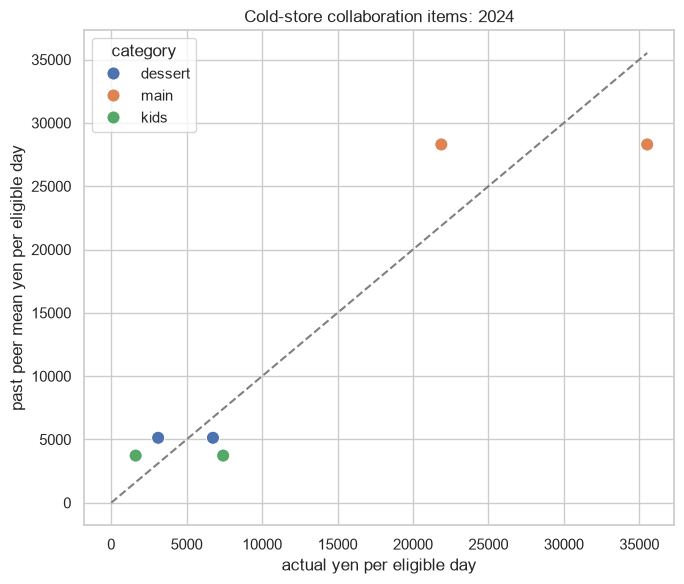

In [4]:
actual=(cold24.groupby(['store_id','item_id'],observed=True).agg(target_days=('sales_amount','size'),actual_daily_mean=('sales_amount','mean'),actual_zero_days=('sales_amount',lambda x:x.eq(0).sum())).reset_index())
comparison=peers24.merge(actual,on=['store_id','item_id'],validate='one_to_one')
comparison['difference']=comparison.peer_daily_mean-comparison.actual_daily_mean
display(comparison.sort_values(['store_id','item_id']))
covered=comparison[comparison.peer_daily_mean.notna()]
print('比較可能ペア:',len(covered),'/',len(comparison))
if len(covered):
    print('日数重み付き平均誤差（他店舗平均 − 実績、円/商品日）:',float(np.average(covered.difference,weights=covered.target_days)))
    print('ペア別平均差の絶対値を日数で重み付け（円/商品日）:',float(np.average(covered.difference.abs(),weights=covered.target_days)))
    fig,ax=plt.subplots(figsize=(7,6));sns.scatterplot(data=covered,x='actual_daily_mean',y='peer_daily_mean',hue='category',s=90,ax=ax)
    upper=max(covered.actual_daily_mean.max(),covered.peer_daily_mean.max());ax.plot([0,upper],[0,upper],ls='--',color='gray');ax.set(title='Cold-store collaboration items: 2024',xlabel='actual yen per eligible day',ylabel='past peer mean yen per eligible day');plt.tight_layout();plt.show()
else: print('他店舗に過去の販売可能日がなく、比較できない。')

## 解釈
- 過去に別店舗での販売があっても、参加店舗、季節、価格、他施策や客層が同一とは限らない。
- 同一商品の過去平均にも0円の日を含め、販売実績のある日のみへの選択バイアスを避ける。販売可能でゼロの理由は不明。
- 2024年の結果は単一の検証年であり、予測手法の優劣を確定しない。2025年の対象店舗の売上は未観測である。